# EDA

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d shubhamgupta012/titanic-dataset

Dataset URL: https://www.kaggle.com/datasets/shubhamgupta012/titanic-dataset
License(s): other
100% 6.67k/6.67k [00:00<00:00, 13.7MB/s]



In [ ]:
import zipfile

with zipfile.ZipFile('titanic-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('titanic_data')

In [ ]:
import os

print(os.listdir('titanic_data'))

['SVMtrain.csv']


In [ ]:
import glob
import pandas as pd

csv_file = glob.glob('titanic_data/*.csv')[0]

print("CSV file:", csv_file)

df = pd.read_csv(csv_file)

print(df.head())
print(df.shape)

CSV file: titanic_data/SVMtrain.csv
   PassengerId  Survived  Pclass     Sex   Age  SibSp  Parch     Fare  \
0            1         0       3    Male  22.0      1      0   7.2500   
1            2         1       1  female  38.0      1      0  71.2833   
2            3         1       3  female  26.0      0      0   7.9250   
3            4         1       1  female  35.0      1      0  53.1000   
4            5         0       3    Male  35.0      0      0   8.0500   

   Embarked  
0         3  
1         1  
2         3  
3         3  
4         3  
(889, 9)


In [ ]:
df.tail()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
884,887,0,2,Male,27.0,0,0,13.00,3
885,888,1,1,female,19.0,0,0,30.00,3
886,889,0,3,female,60.0,1,2,23.45,3
887,890,1,1,Male,26.0,0,0,30.00,1
888,891,0,3,Male,32.0,0,0,7.75,2


In [ ]:
print("Columns in dataset:")
print(df.columns)

Columns in dataset:
Index(['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
       'Fare', 'Embarked'],
      dtype='object')


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 889 entries, 0 to 888
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  889 non-null    int64  
 1   Survived     889 non-null    int64  
 2   Pclass       889 non-null    int64  
 3   Sex          889 non-null    object 
 4   Age          889 non-null    float64
 5   SibSp        889 non-null    int64  
 6   Parch        889 non-null    int64  
 7   Fare         889 non-null    float64
 8   Embarked     889 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 62.6+ KB


In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Embarked
count,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000
mean,446.000000,0.382452,2.311586,35.686355,0.524184,0.382452,32.096681,2.535433
std,256.998173,0.486260,0.834700,17.756733,1.103705,0.806761,49.697504,0.792088
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,1.000000
25%,224.000000,0.000000,2.000000,22.000000,0.000000,0.000000,7.895800,2.000000
50%,446.000000,0.000000,3.000000,32.000000,0.000000,0.000000,14.454200,3.000000
75%,668.000000,1.000000,3.000000,54.000000,1.000000,0.000000,31.000000,3.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,3.000000


In [ ]:
# Compute correlation matrix (only numeric columns)
corr_matrix = df.corr(numeric_only=True)

corr_matrix

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Embarked
PassengerId,1.000000,-0.005028,-0.035330,0.008341,-0.057686,-0.001657,0.012703,0.013166
Survived,-0.005028,1.000000,-0.335549,-0.116558,-0.034040,0.083151,0.255290,-0.169718
Pclass,-0.035330,-0.335549,1.000000,-0.122449,0.081656,0.016824,-0.548193,0.164681
Age,0.008341,-0.116558,-0.122449,1.000000,-0.156777,-0.215191,-0.003307,-0.124894
SibSp,-0.057686,-0.034040,0.081656,-0.156777,1.000000,0.414542,0.160887,0.068900
Parch,-0.001657,0.083151,0.016824,-0.215191,0.414542,1.000000,0.217532,0.040449
Fare,0.012703,0.255290,-0.548193,-0.003307,0.160887,0.217532,1.000000,-0.226311
Embarked,0.013166,-0.169718,0.164681,-0.124894,0.068900,0.040449,-0.226311,1.000000


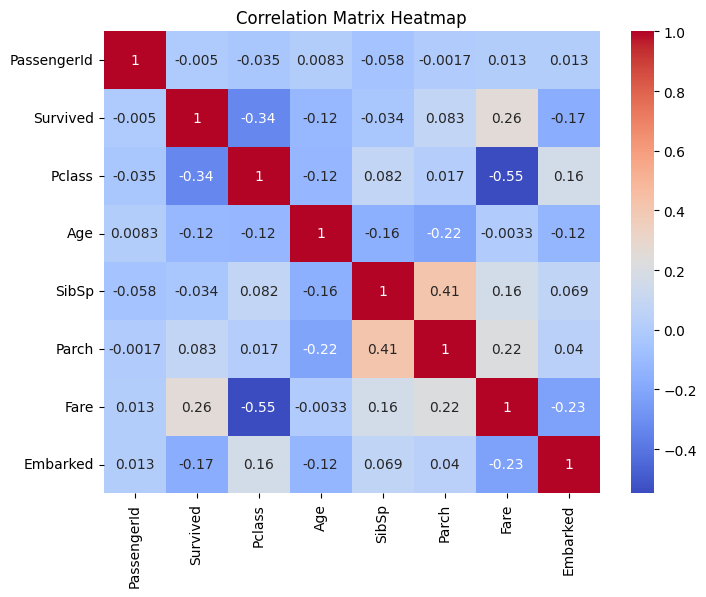

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix Heatmap")
plt.show()

In [ ]:
# Find highly correlated feature pairs (> 0.8)

corr_matrix = df.select_dtypes(include='number').corr()

high_corr = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.8:
            high_corr.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                corr_matrix.iloc[i, j]
            ))

print("Highly Correlated Feature Pairs:")

for pair in high_corr:
    print(pair)

Highly Correlated Feature Pairs:


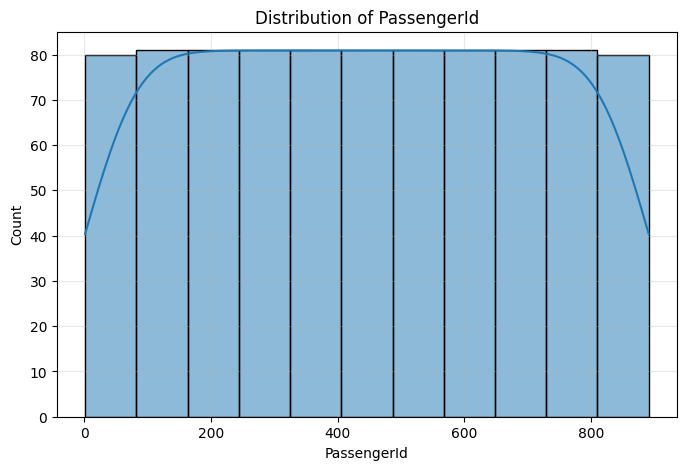

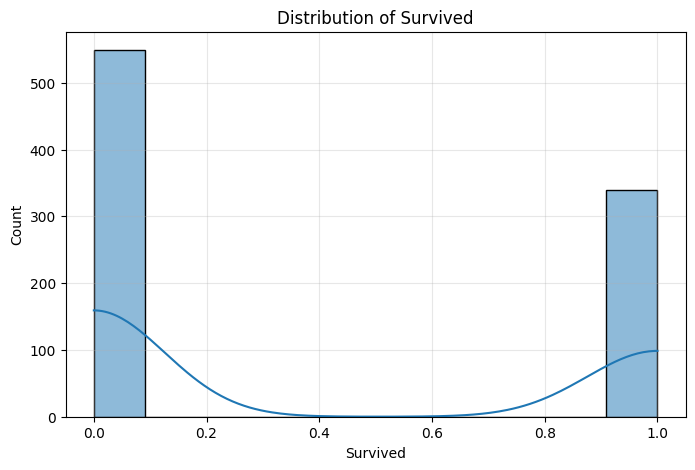

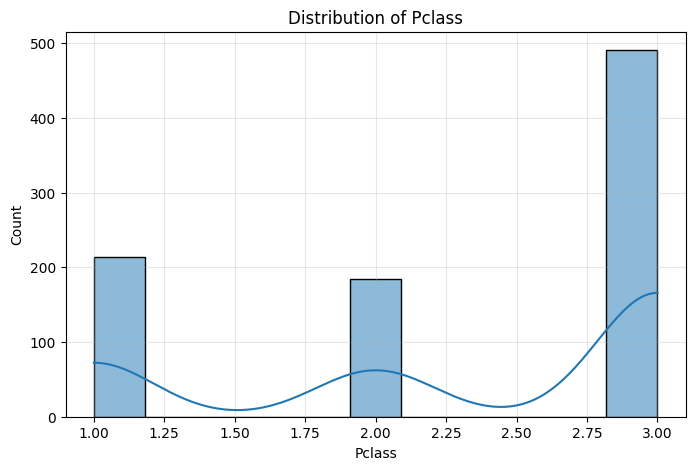

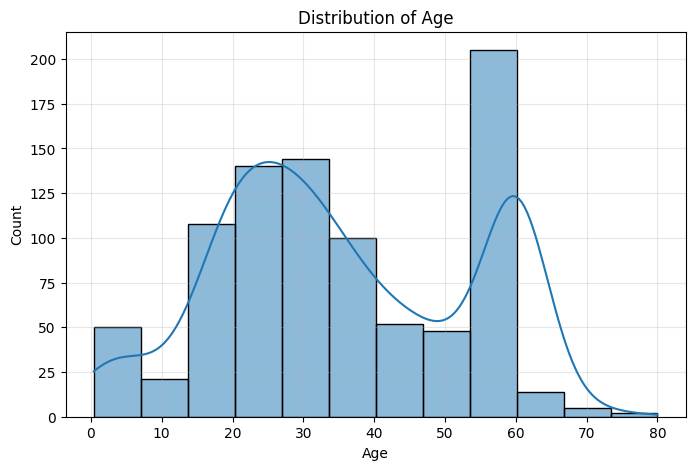

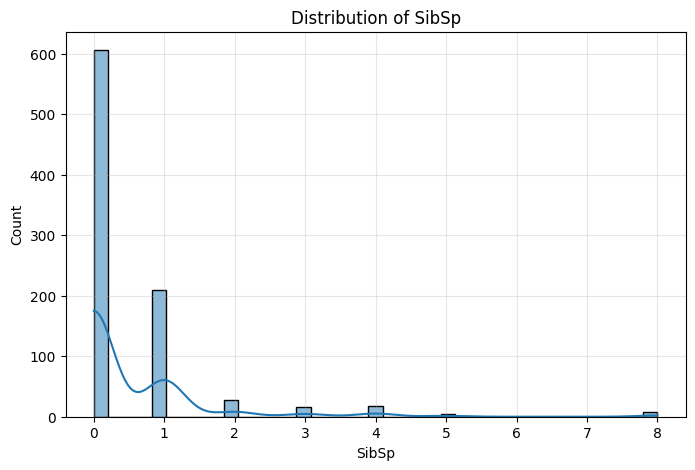

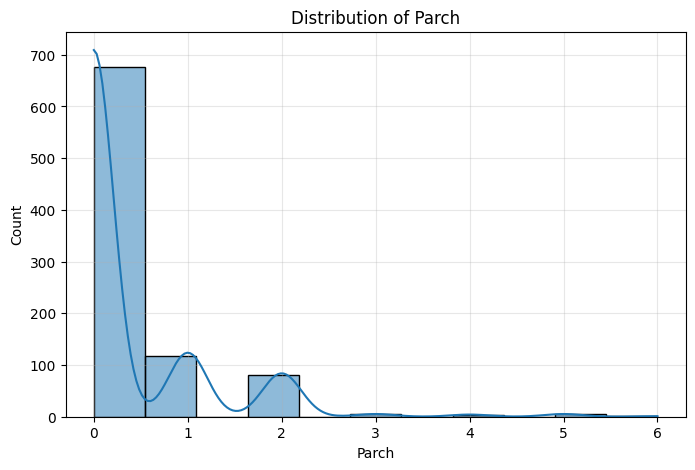

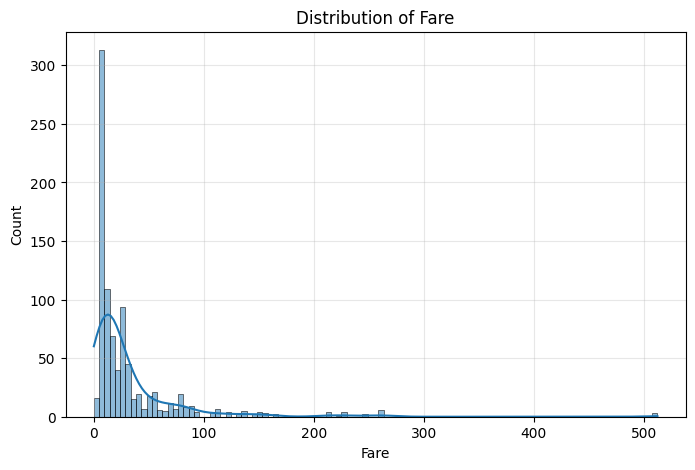

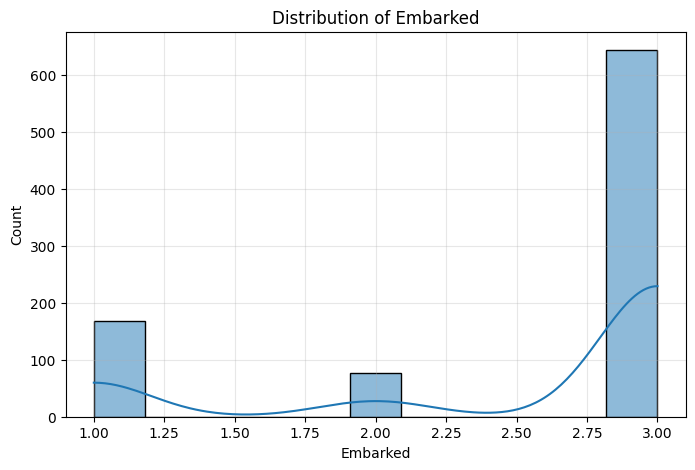

In [ ]:
# HISTOGRAM

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 5))

    sns.histplot(data=df, x=col, kde=True)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.grid(True, alpha=0.3)

    plt.show()

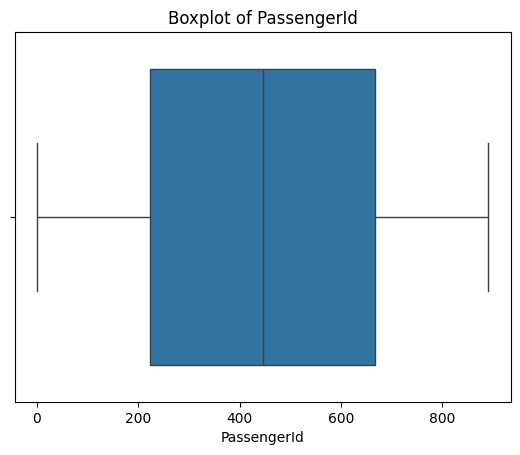

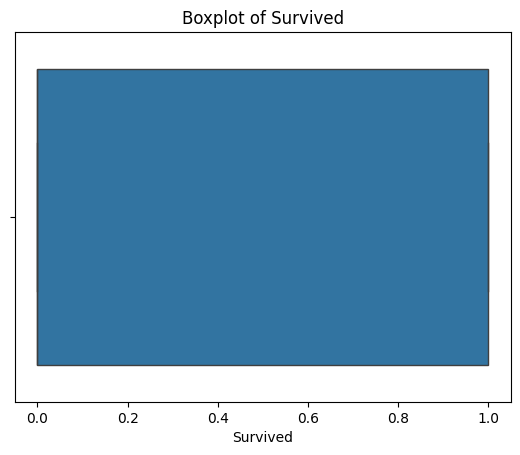

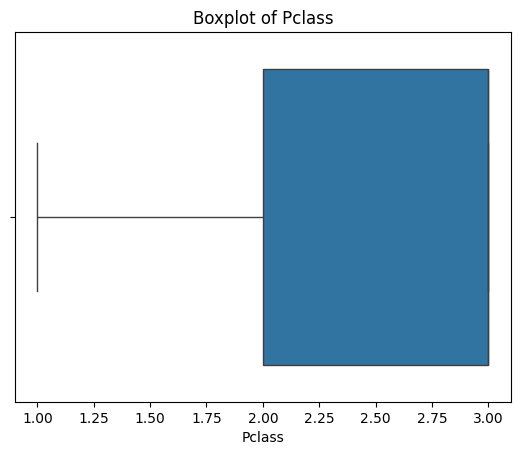

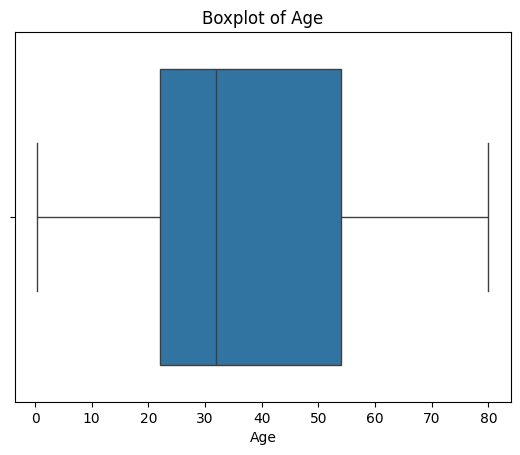

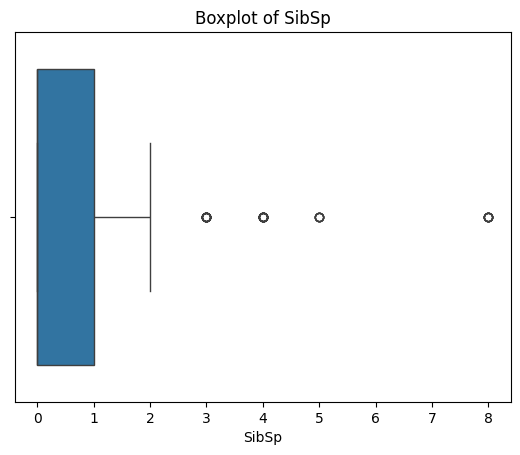

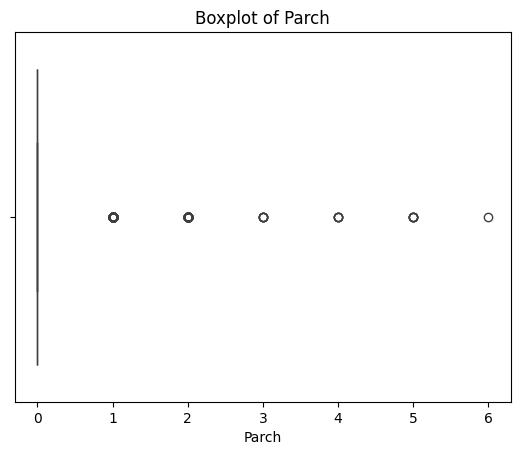

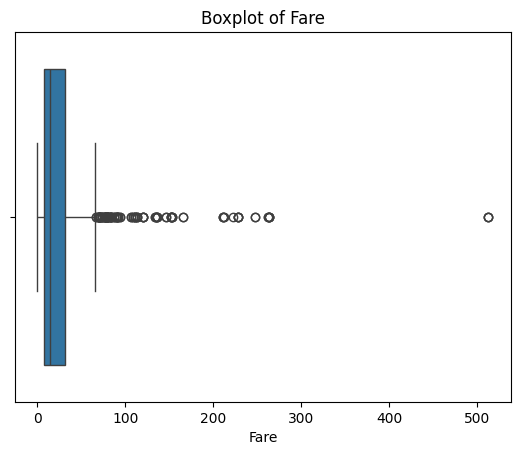

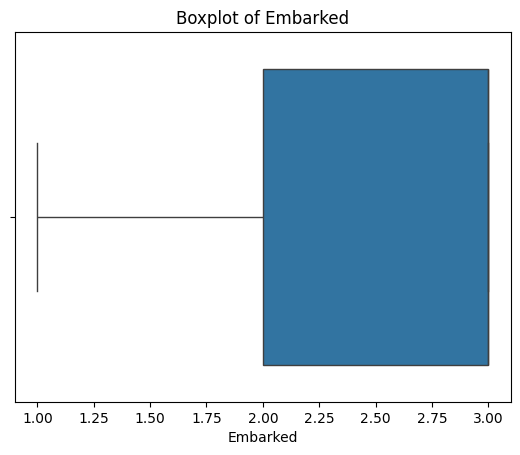

In [ ]:
# BOXPLOT
import seaborn as sns

# Boxplot for each numeric column
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

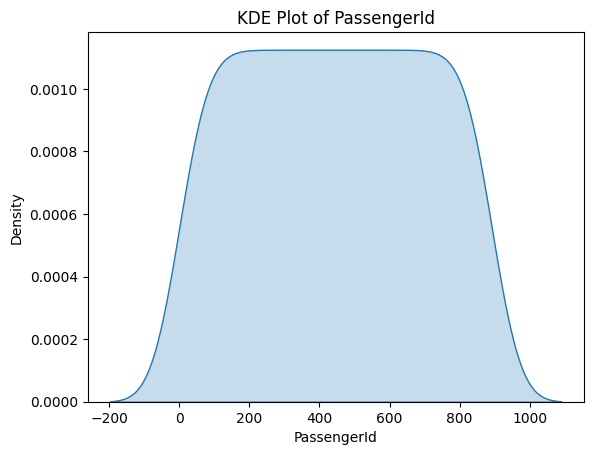

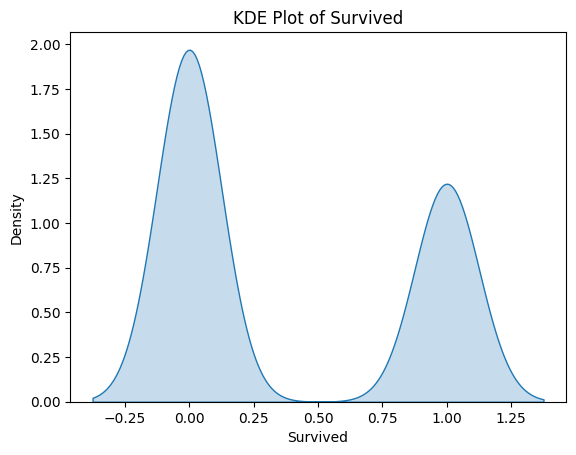

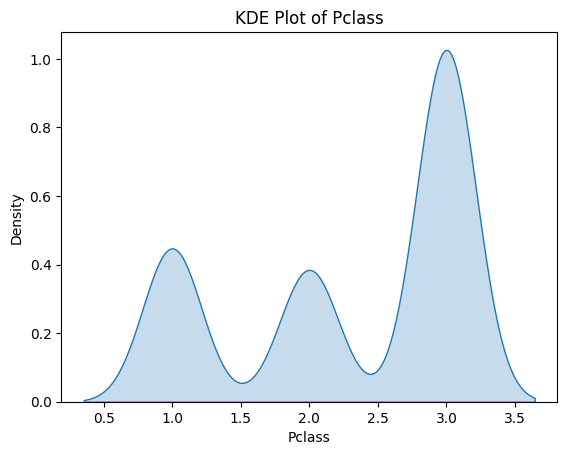

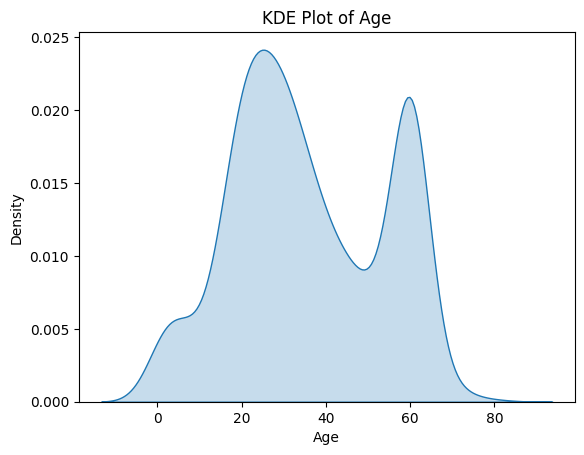

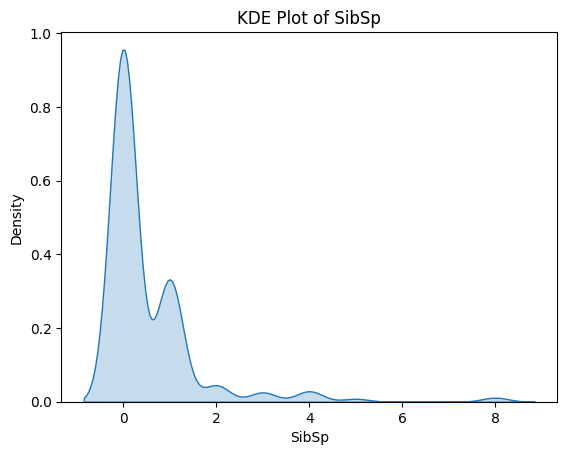

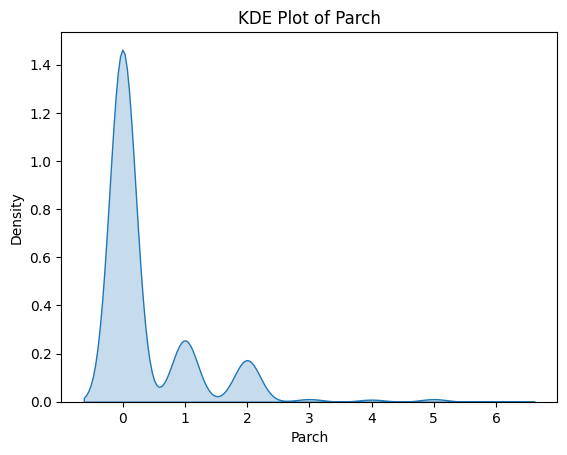

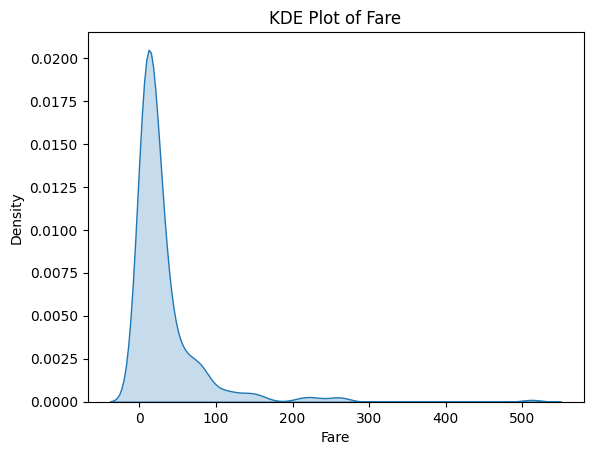

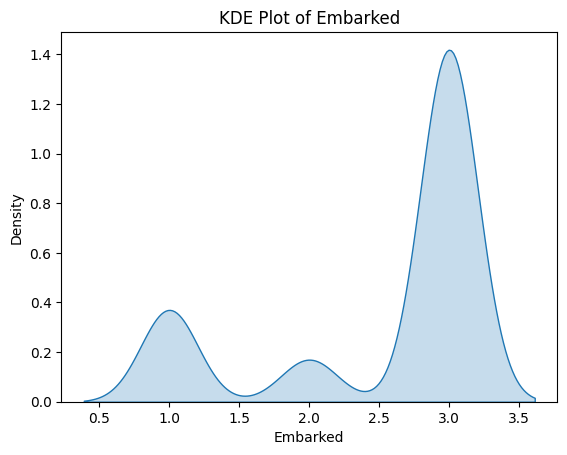

In [ ]:
# KDE Plot (Smooth Distribution Curve)
for col in df.select_dtypes(include='number').columns:
    plt.figure()
    sns.kdeplot(df[col], fill=True)
    plt.title(f"KDE Plot of {col}")
    plt.show()

In [ ]:
# Skewness Calculation

df.skew(numeric_only=True)

,0
PassengerId,0.000000
Survived,0.484568
Pclass,-0.636998
Age,0.104457
SibSp,3.691058
Parch,2.745160
Fare,4.801440
Embarked,-1.261367


In [ ]:
# Example statistics
# Calculate average, maximum and minimum Fare

print("Average Fare:", df["Fare"].mean())

print("Maximum Fare:", df["Fare"].max())

print("Minimum Fare:", df["Fare"].min())

Average Fare: 32.09668087739032
Maximum Fare: 512.3292
Minimum Fare: 0.0


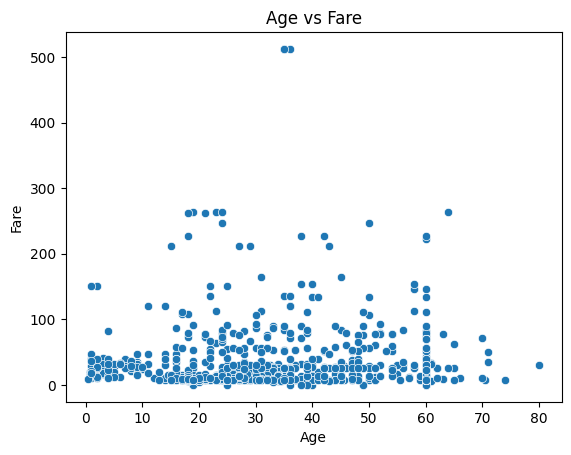

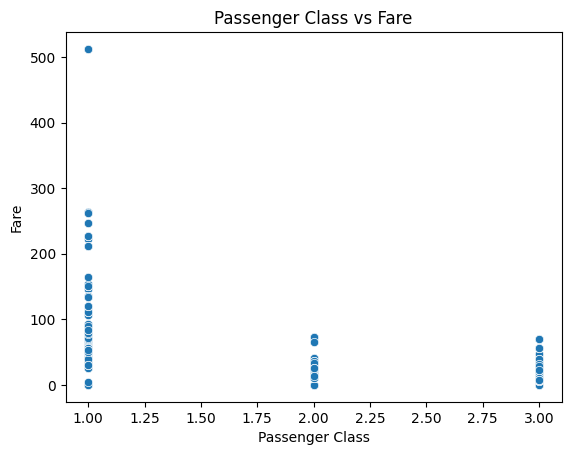

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Age vs Fare
sns.scatterplot(x="Age", y="Fare", data=df)
plt.title("Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()

# Pclass vs Fare
sns.scatterplot(x="Pclass", y="Fare", data=df)
plt.title("Passenger Class vs Fare")
plt.xlabel("Passenger Class")
plt.ylabel("Fare")
plt.show()

In [ ]:
# Average Fare by Passenger Class

if "Pclass" in df.columns and "Fare" in df.columns:

    avg_fare = df.groupby("Pclass")["Fare"].mean()

    print("Average Fare by Passenger Class:")
    print(avg_fare)

else:
    print("Required columns not found in the dataset.")

Average Fare by Passenger Class:
Pclass
1    84.193516
2    20.662183
3    13.675550
Name: Fare, dtype: float64


In [ ]:
# Q1. Display the first 10 rows
print(df.head(10))

   PassengerId  Survived  Pclass     Sex   Age  SibSp  Parch     Fare  \
0            1         0       3    Male  22.0      1      0   7.2500   
1            2         1       1  female  38.0      1      0  71.2833   
2            3         1       3  female  26.0      0      0   7.9250   
3            4         1       1  female  35.0      1      0  53.1000   
4            5         0       3    Male  35.0      0      0   8.0500   
5            6         0       3    Male  60.0      0      0   8.4583   
6            7         0       1    Male  54.0      0      0  51.8625   
7            8         0       3    Male   2.0      3      1  21.0750   
8            9         1       3  female  27.0      0      2  11.1333   
9           10         1       2  female  14.0      1      0  30.0708   

   Embarked  
0         3  
1         1  
2         3  
3         3  
4         3  
5         2  
6         3  
7         3  
8         3  
9         1  


In [ ]:
# Q2. Find the number of rows and columns
print(df.shape)

(889, 9)


In [ ]:
# Q3. Print all column names
print(df.columns)

Index(['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
       'Fare', 'Embarked'],
      dtype='object')


In [ ]:
# Q4. Check data types
print(df.dtypes)

PassengerId      int64
Survived         int64
Pclass           int64
Sex             object
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked         int64
dtype: object


In [ ]:
# Q5. Find missing values
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64


In [ ]:
# Q6. Calculate mean, median, and standard deviation of Fare
print("Mean:", df['Fare'].mean())
print("Median:", df['Fare'].median())
print("Standard Deviation:", df['Fare'].std())

Mean: 32.09668087739032
Median: 14.4542
Standard Deviation: 49.69750431670801


In [ ]:
# Q7. Find maximum and minimum Age
print("Maximum Age:", df['Age'].max())
print("Minimum Age:", df['Age'].min())

Maximum Age: 80.0
Minimum Age: 0.42


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Q8. Select numerical columns
numerical_df = df.select_dtypes(include=np.number)
print(numerical_df.head())

   PassengerId  Survived  Pclass   Age  SibSp  Parch     Fare  Embarked
0            1         0       3  22.0      1      0   7.2500         3
1            2         1       1  38.0      1      0  71.2833         1
2            3         1       3  26.0      0      0   7.9250         3
3            4         1       1  35.0      1      0  53.1000         3
4            5         0       3  35.0      0      0   8.0500         3


In [ ]:
# Q9. Compute correlation matrix
corr_matrix = numerical_df.corr()
print(corr_matrix)

             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000 -0.005028 -0.035330  0.008341 -0.057686 -0.001657   
Survived       -0.005028  1.000000 -0.335549 -0.116558 -0.034040  0.083151   
Pclass         -0.035330 -0.335549  1.000000 -0.122449  0.081656  0.016824   
Age             0.008341 -0.116558 -0.122449  1.000000 -0.156777 -0.215191   
SibSp          -0.057686 -0.034040  0.081656 -0.156777  1.000000  0.414542   
Parch          -0.001657  0.083151  0.016824 -0.215191  0.414542  1.000000   
Fare            0.012703  0.255290 -0.548193 -0.003307  0.160887  0.217532   
Embarked        0.013166 -0.169718  0.164681 -0.124894  0.068900  0.040449   

                 Fare  Embarked  
PassengerId  0.012703  0.013166  
Survived     0.255290 -0.169718  
Pclass      -0.548193  0.164681  
Age         -0.003307 -0.124894  
SibSp        0.160887  0.068900  
Parch        0.217532  0.040449  
Fare         1.000000 -0.226311  
Embarked    -0.226311  1.

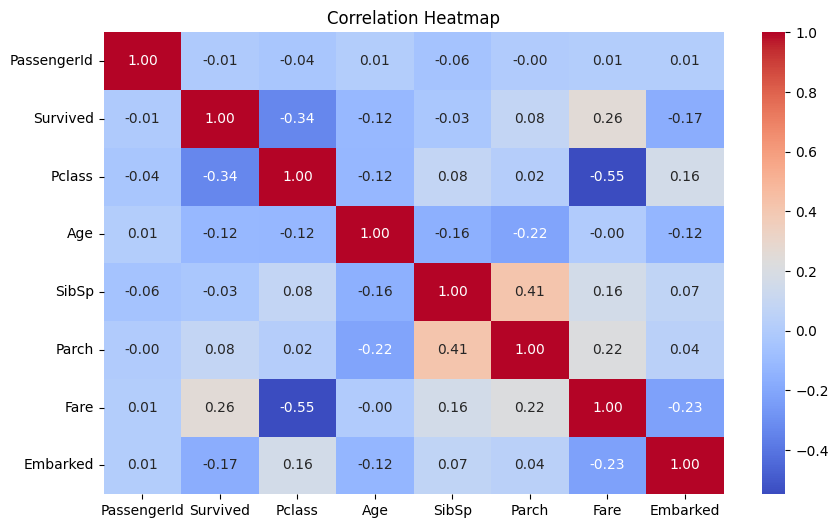

In [ ]:
# Q10. Plot correlation heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Q11. Find and sort correlations with Survived
correlation = corr_matrix['Survived'].sort_values(ascending=False)
print(correlation)

Survived       1.000000
Fare           0.255290
Parch          0.083151
PassengerId   -0.005028
SibSp         -0.034040
Age           -0.116558
Embarked      -0.169718
Pclass        -0.335549
Name: Survived, dtype: float64


In [ ]:
# Q12. Identify highly correlated feature pairs
corr_matrix = numerical_df.corr()

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.7:
            print(
                corr_matrix.columns[i],
                "and",
                corr_matrix.columns[j],
                ":",
                corr_matrix.iloc[i, j]
            )

In [ ]:
# Q13. Extract highly correlated feature pairs
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.7:
            high_corr_pairs.append(
                (corr_matrix.columns[i], corr_matrix.columns[j])
            )

print(high_corr_pairs)

[]


In [ ]:
# Q14. Drop one feature from each highly correlated pair
features_to_drop = list(set(pair[1] for pair in high_corr_pairs))

df_reduced = numerical_df.drop(columns=features_to_drop)

print(df_reduced.head())

   PassengerId  Survived  Pclass   Age  SibSp  Parch     Fare  Embarked
0            1         0       3  22.0      1      0   7.2500         3
1            2         1       1  38.0      1      0  71.2833         1
2            3         1       3  26.0      0      0   7.9250         3
3            4         1       1  35.0      1      0  53.1000         3
4            5         0       3  35.0      0      0   8.0500         3


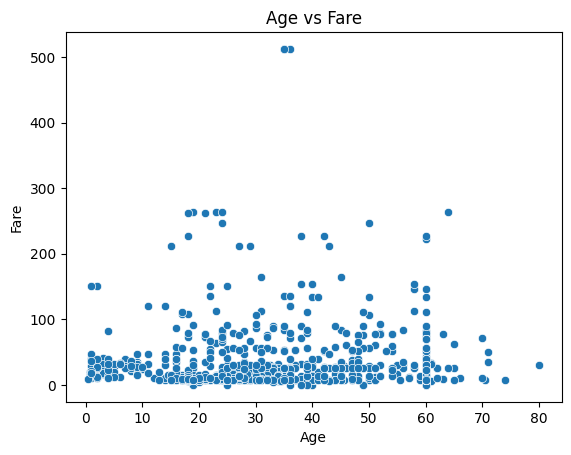

In [ ]:
# Q15. Plot scatter plot between Age and Fare
sns.scatterplot(data=df, x='Age', y='Fare')
plt.title("Age vs Fare")
plt.show()

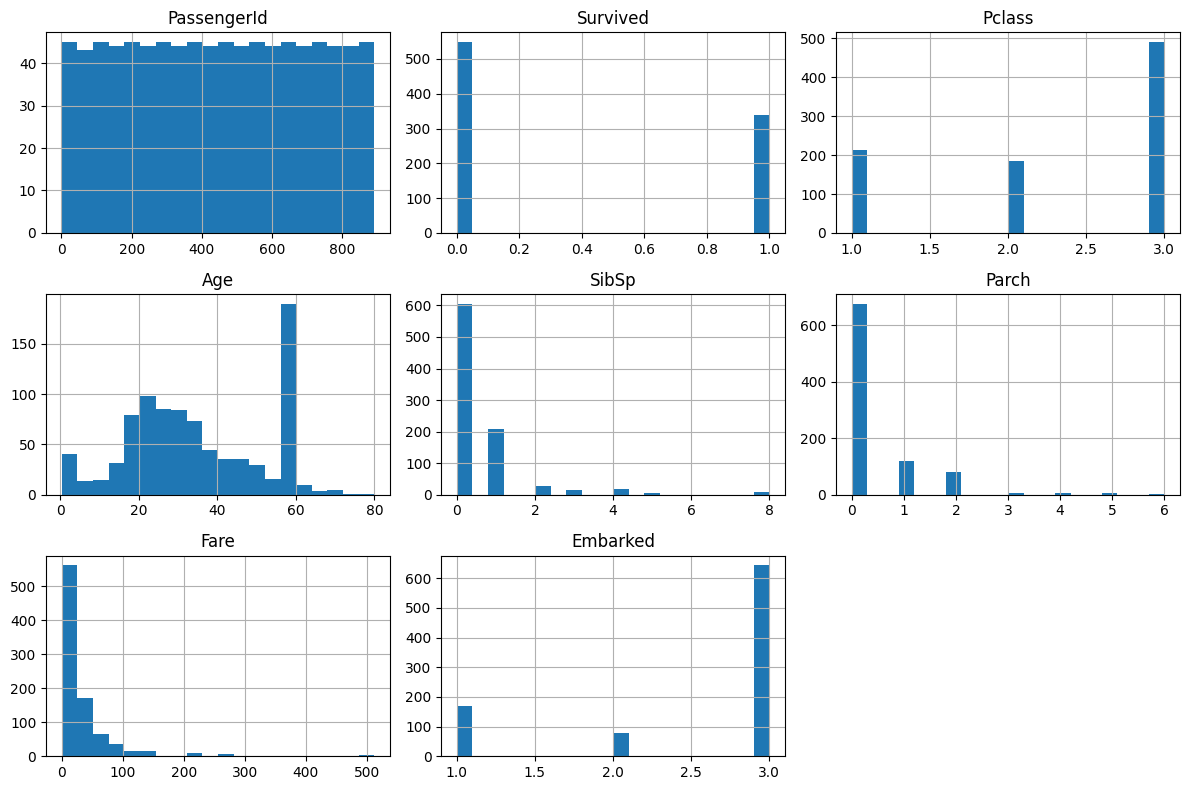

In [ ]:
# Q16. Plot histograms for all numerical columns
numerical_df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

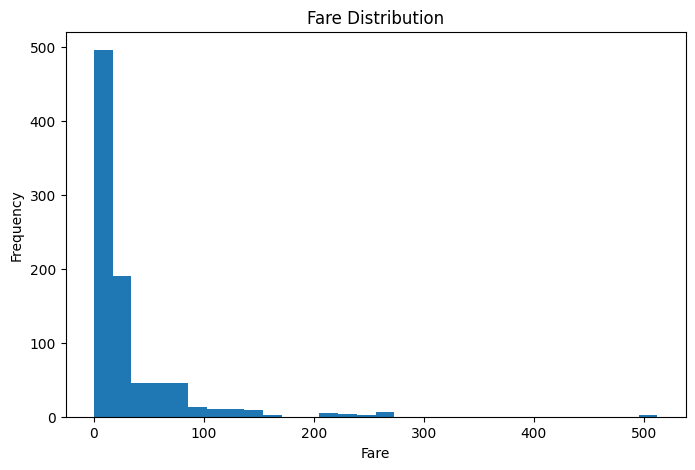

In [ ]:
# Q17. Plot histogram of Fare with 30 bins
plt.figure(figsize=(8, 5))
plt.hist(df['Fare'].dropna(), bins=30)
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

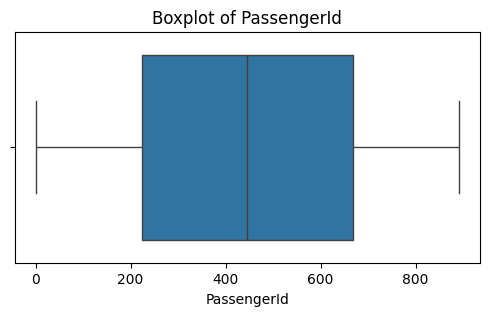

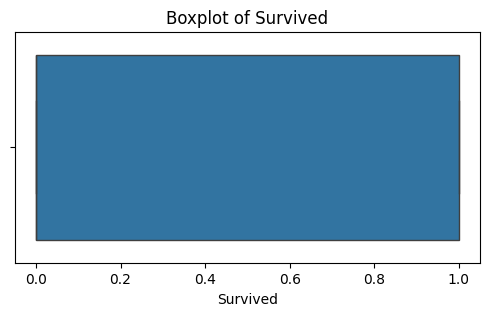

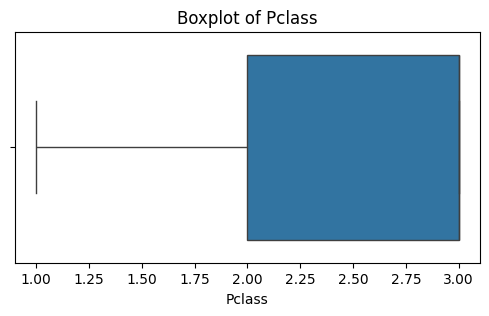

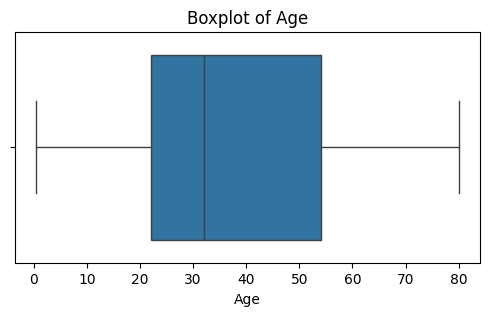

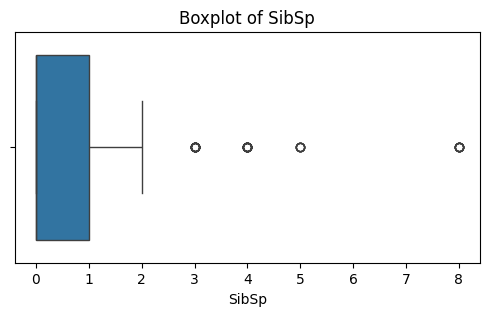

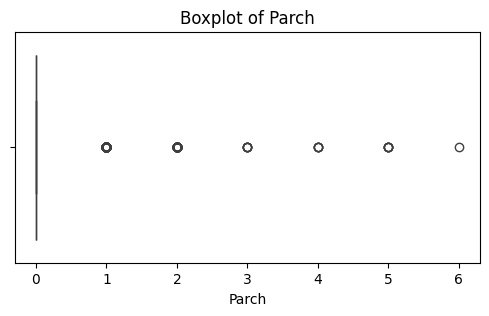

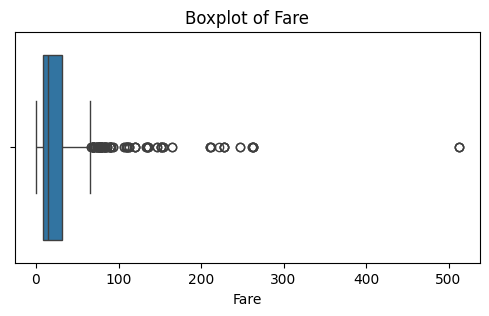

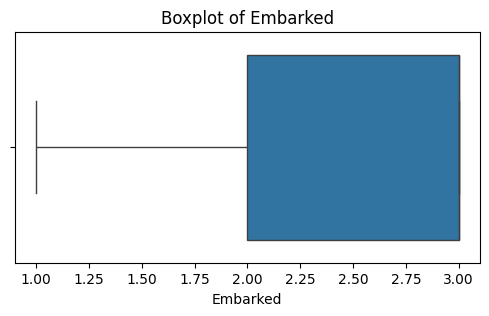

In [ ]:
# Q18. Create boxplots for numerical columns
for col in numerical_df.columns:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [ ]:
# Q19. Identify outliers using IQR
for col in numerical_df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

PassengerId Outliers: 0
Survived Outliers: 0
Pclass Outliers: 0
Age Outliers: 0
SibSp Outliers: 46
Parch Outliers: 213
Fare Outliers: 114
Embarked Outliers: 0


In [ ]:
# Q20. Calculate skewness
print(numerical_df.skew())

PassengerId    0.000000
Survived       0.484568
Pclass        -0.636998
Age            0.104457
SibSp          3.691058
Parch          2.745160
Fare           4.801440
Embarked      -1.261367
dtype: float64


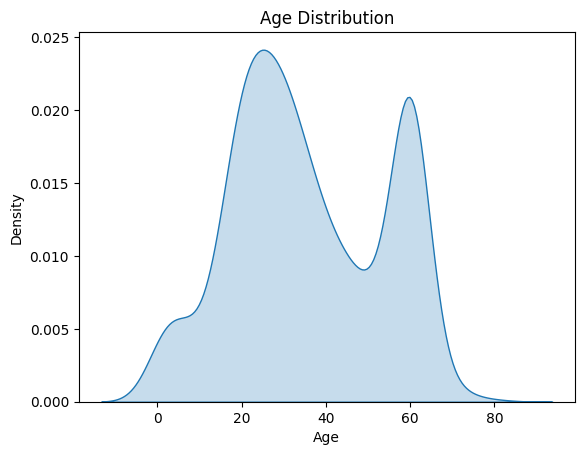

In [ ]:
# Q21. Plot KDE for Age
sns.kdeplot(data=df, x='Age', fill=True)
plt.title("Age Distribution")
plt.show()

In [ ]:
# Q23. Count right-skewed numerical features
skew_values = numerical_df.skew()

right_skewed = skew_values[skew_values > 0]

print("Right-skewed features:")
print(right_skewed)

print("Total:", len(right_skewed))

Right-skewed features:
Survived    0.484568
Age         0.104457
SibSp       3.691058
Parch       2.745160
Fare        4.801440
dtype: float64
Total: 5


In [ ]:
# Q24. Find average Fare grouped by Pclass
print(df.groupby('Pclass')['Fare'].mean())

Pclass
1    84.193516
2    20.662183
3    13.675550
Name: Fare, dtype: float64


In [ ]:
# Q25. Find top 3 records with highest Fare
print(df.nlargest(3, 'Fare'))

     PassengerId  Survived  Pclass     Sex   Age  SibSp  Parch      Fare  \
257          259         1       1  female  35.0      0      0  512.3292   
678          680         1       1    Male  36.0      0      1  512.3292   
736          738         1       1    Male  35.0      0      0  512.3292   

     Embarked  
257         1  
678         1  
736         1  


In [ ]:
# Q26. Find rows where Fare is greater than average
average_fare = df['Fare'].mean()

print(df[df['Fare'] > average_fare])

     PassengerId  Survived  Pclass     Sex   Age  SibSp  Parch      Fare  \
1              2         1       1  female  38.0      1      0   71.2833   
3              4         1       1  female  35.0      1      0   53.1000   
6              7         0       1    Male  54.0      0      0   51.8625   
23            24         1       1    Male  28.0      0      0   35.5000   
27            28         0       1    Male  19.0      3      2  263.0000   
..           ...       ...     ...     ...   ...    ...    ...       ...   
854          857         1       1  female  45.0      1      1  164.8667   
861          864         0       3  female  60.0      8      2   69.5500   
865          868         0       1    Male  31.0      0      0   50.4958   
869          872         1       1  female  47.0      1      1   52.5542   
877          880         1       1  female  56.0      0      1   83.1583   

     Embarked  
1           1  
3           3  
6           3  
23          3  
27     

In [ ]:
# Q27. Compare average Fare for older and younger passengers
average_age = df['Age'].mean()

high_age = df[df['Age'] > average_age]
low_age = df[df['Age'] <= average_age]

print("Average Fare for high Age:", high_age['Fare'].mean())
print("Average Fare for low Age:", low_age['Fare'].mean())

Average Fare for high Age: 33.935883673469384
Average Fare for low Age: 30.64604205231388


In [ ]:
# Q28. Create high_fare column
mean_fare = df['Fare'].mean()

df['high_fare'] = (df['Fare'] > mean_fare).astype(int)

print(df[['Fare', 'high_fare']].head())

      Fare  high_fare
0   7.2500          0
1  71.2833          1
2   7.9250          0
3  53.1000          1
4   8.0500          0


In [ ]:
# Q29. Count records in high_fare category
print(df['high_fare'].value_counts())

high_fare
0    680
1    209
Name: count, dtype: int64


In [ ]:
# Q30. Find correlation for high_fare records
high_fare_df = df[df['high_fare'] == 1]

print(high_fare_df.select_dtypes(include=np.number).corr())

             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000  0.158522  0.041320  0.064502 -0.035137  0.069695   
Survived        0.158522  1.000000 -0.358101 -0.089002 -0.302739 -0.196360   
Pclass          0.041320 -0.358101  1.000000 -0.182619  0.596778  0.438858   
Age             0.064502 -0.089002 -0.182619  1.000000 -0.033482 -0.209051   
SibSp          -0.035137 -0.302739  0.596778 -0.033482  1.000000  0.367780   
Parch           0.069695 -0.196360  0.438858 -0.209051  0.367780  1.000000   
Fare            0.013215  0.193338 -0.298143 -0.025634 -0.101613  0.056747   
Embarked        0.008616 -0.224595  0.337873 -0.080358  0.246577  0.179174   
high_fare            NaN       NaN       NaN       NaN       NaN       NaN   

                 Fare  Embarked  high_fare  
PassengerId  0.013215  0.008616        NaN  
Survived     0.193338 -0.224595        NaN  
Pclass      -0.298143  0.337873        NaN  
Age         -0.025634 -0.080358        

In [ ]:
# Q31. Function to detect outliers using IQR
def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return data[(data[column] < lower) | (data[column] > upper)]

print(detect_outliers(df, 'Fare'))

     PassengerId  Survived  Pclass     Sex   Age  SibSp  Parch      Fare  \
1              2         1       1  female  38.0      1      0   71.2833   
27            28         0       1    Male  19.0      3      2  263.0000   
31            32         1       1  female  60.0      1      0  146.5208   
34            35         0       1    Male  28.0      1      0   82.1708   
52            53         1       1  female  49.0      1      0   76.7292   
..           ...       ...     ...     ...   ...    ...    ...       ...   
844          847         0       3    Male  60.0      8      2   69.5500   
847          850         1       1  female  60.0      1      0   89.1042   
854          857         1       1  female  45.0      1      1  164.8667   
861          864         0       3  female  60.0      8      2   69.5500   
877          880         1       1  female  56.0      0      1   83.1583   

     Embarked  high_fare  
1           1          1  
27          3          1  
31    

In [ ]:
# Q32. Remove Fare outliers using IQR
Q1 = df['Fare'].quantile(0.25)
Q3 = df['Fare'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df['Fare'] >= lower) &
    (df['Fare'] <= upper)
].copy()

print("Original shape:", df.shape)
print("After removing outliers:", df_no_outliers.shape)

Original shape: (889, 10)
After removing outliers: (775, 10)


In [ ]:
# Q36. Find features correlated with Survived
corr = numerical_df.corr()['Survived'].drop('Survived')

print(corr[abs(corr) > 0.5])

Series([], Name: Survived, dtype: float64)


Survived
0    549
1    340
Name: count, dtype: int64
Survived
0    61.754781
1    38.245219
Name: proportion, dtype: float64


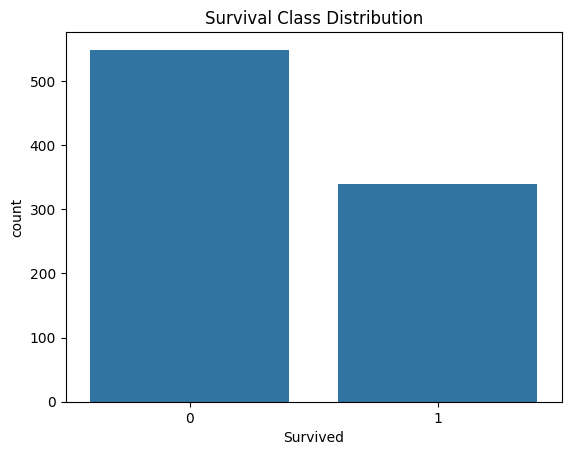

In [ ]:
# Q37. Check target class balance
print(df['Survived'].value_counts())

print(df['Survived'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='Survived')
plt.title("Survival Class Distribution")
plt.show()

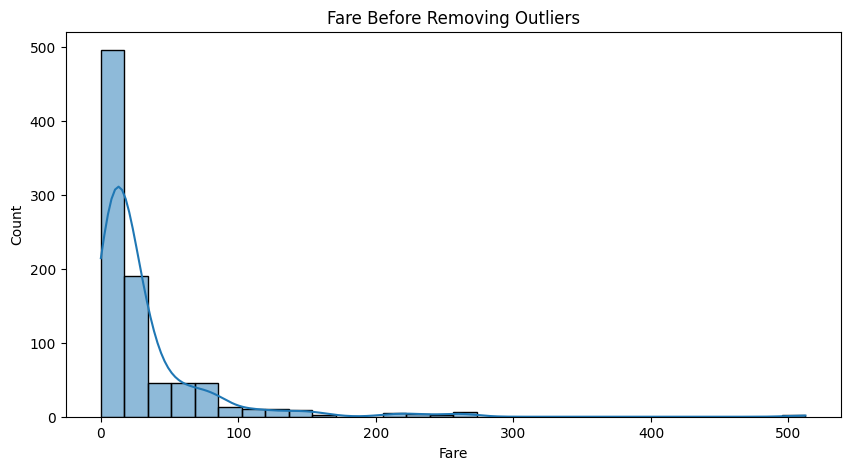

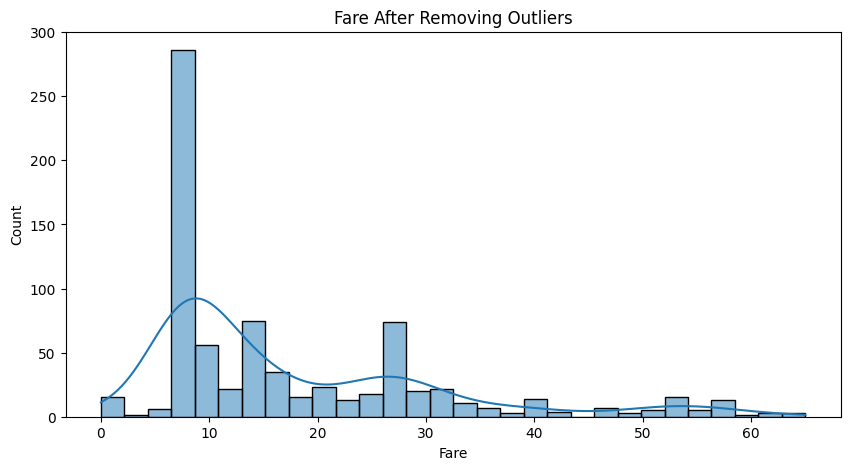

In [ ]:
# Q38. Compare Fare before and after removing outliers
plt.figure(figsize=(10, 5))

sns.histplot(df['Fare'], bins=30, kde=True)
plt.title("Fare Before Removing Outliers")
plt.show()

plt.figure(figsize=(10, 5))

sns.histplot(df_no_outliers['Fare'], bins=30, kde=True)
plt.title("Fare After Removing Outliers")
plt.show()

In [ ]:
# Q39. Create numerical summary report
report = pd.DataFrame({
    'Mean': numerical_df.mean(),
    'Skewness': numerical_df.skew(),
    'Outliers_Count': [
        len(detect_outliers(df, col))
        for col in numerical_df.columns
    ]
})

print(report)

                   Mean  Skewness  Outliers_Count
PassengerId  446.000000  0.000000               0
Survived       0.382452  0.484568               0
Pclass         2.311586 -0.636998               0
Age           35.686355  0.104457               0
SibSp          0.524184  3.691058              46
Parch          0.382452  2.745160             213
Fare          32.096681  4.801440             114
Embarked       2.535433 -1.261367               0


Shape: (889, 10)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'high_fare']

Data types:
PassengerId      int64
Survived         int64
Pclass           int64
Sex             object
Age            float64
SibSp            int64
Parch            int64
Fare           float64
Embarked         int64
high_fare        int64
dtype: object

Missing values:
PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
high_fare      0
dtype: int64

Statistical summary:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   889.000000  889.000000  889.000000  889.000000  889.000000   
mean    446.000000    0.382452    2.311586   35.686355    0.524184   
std     256.998173    0.486260    0.834700   17.756733    1.103705   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     224.000000    0.000000    2.

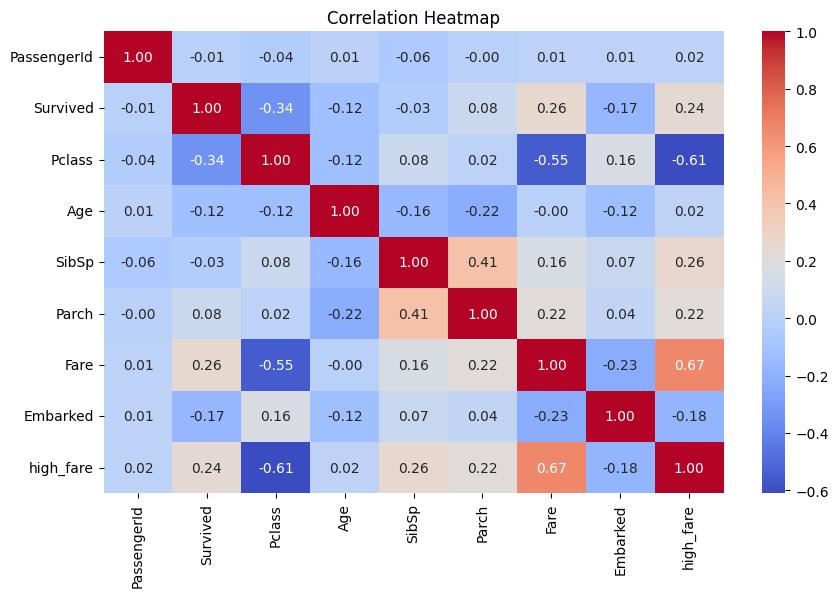

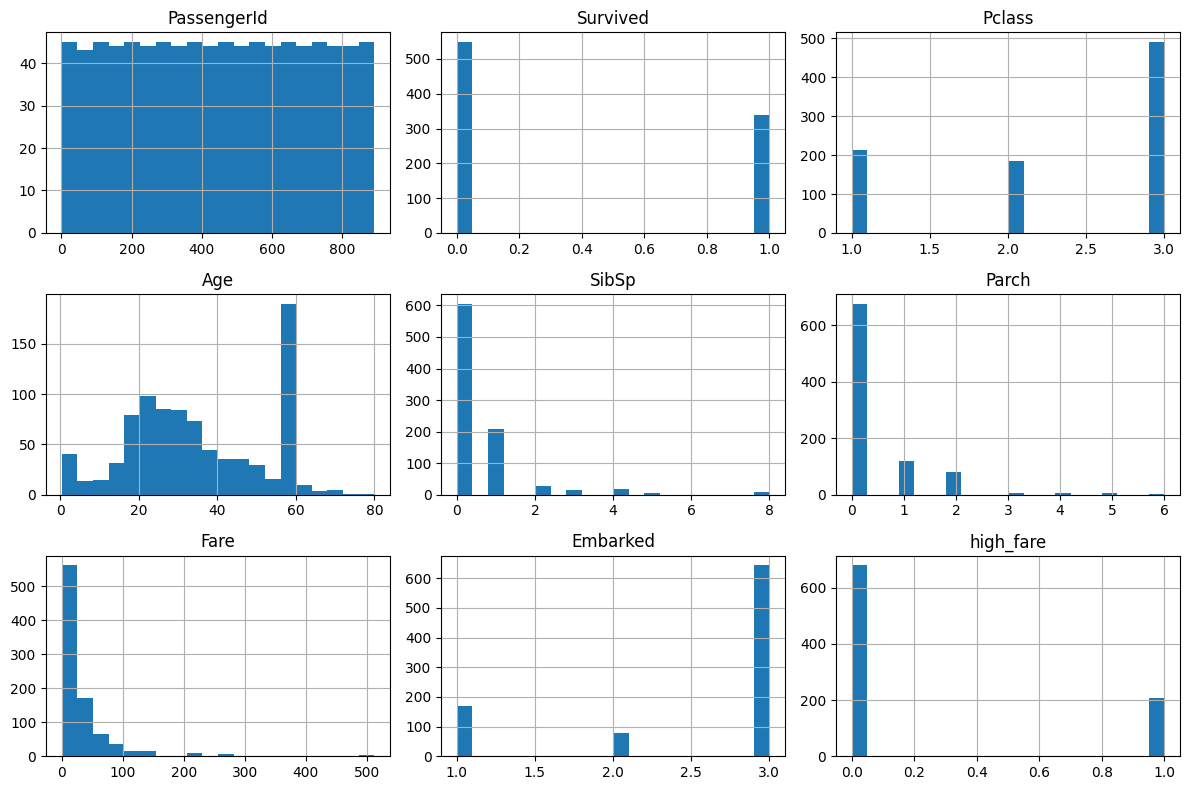


Skewness:
PassengerId    0.000000
Survived       0.484568
Pclass        -0.636998
Age            0.104457
SibSp          3.691058
Parch          2.745160
Fare           4.801440
Embarked      -1.261367
high_fare      1.251489
dtype: float64

Outlier counts:
PassengerId : 0
Survived : 0
Pclass : 0
Age : 0
SibSp : 46
Parch : 213
Fare : 114
Embarked : 0
high_fare : 209


In [ ]:
# Q40. Reusable function for full EDA
def full_eda(data):
    numerical = data.select_dtypes(include=np.number)

    # Basic information
    print("Shape:", data.shape)
    print("\nColumn names:")
    print(data.columns.tolist())

    print("\nData types:")
    print(data.dtypes)

    print("\nMissing values:")
    print(data.isnull().sum())

    print("\nStatistical summary:")
    print(numerical.describe())

    # Correlation heatmap
    if numerical.shape[1] >= 2:
        plt.figure(figsize=(10, 6))
        sns.heatmap(
            numerical.corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f'
        )
        plt.title("Correlation Heatmap")
        plt.show()

    # Histograms
    numerical.hist(figsize=(12, 8), bins=20)
    plt.tight_layout()
    plt.show()

    # Skewness
    print("\nSkewness:")
    print(numerical.skew())

    # Outlier counts
    print("\nOutlier counts:")
    for col in numerical.columns:
        outliers = detect_outliers(data, col)
        print(col, ":", len(outliers))


full_eda(df)